# Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path("../data/raw")
OUTPUT_DIR = Path("../outputs/charts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully")

Libraries imported successfully


# Load the Excel dataset

In [7]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("Files in current directory:")

for file in Path.cwd().iterdir():
    print(file.name)

Current directory: c:\Users\dipay\OneDrive\Desktop\Code\ShadowFox
Files in current directory:
Beginner_Level.ipynb
Intermidiate_Level.ipynb
Online_Retail_Analysis.xlsx
online_retail_II.xlsx
Raw_Data.xlsx
requirements.txt


In [8]:
from pathlib import Path

for file in Path.cwd().rglob("*"):
    if file.is_file() and file.suffix.lower() in [".xlsx", ".xls", ".csv"]:
        print(file.resolve())

C:\Users\dipay\OneDrive\Desktop\Code\ShadowFox\Online_Retail_Analysis.xlsx
C:\Users\dipay\OneDrive\Desktop\Code\ShadowFox\online_retail_II.xlsx
C:\Users\dipay\OneDrive\Desktop\Code\ShadowFox\Raw_Data.xlsx


In [10]:
df = pd.read_excel(
    r"C:\Users\dipay\OneDrive\Desktop\Code\ShadowFox\Raw_Data.xlsx"
)

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


# Understand and audit the data

Check the dataset size

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

Rows: 525461
Columns: 8
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


Inspect the columns and data types

In [ ]:
print(df.columns.tolist())
display(df.dtypes)

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

Check missing values

In [ ]:
missing = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (
        missing / len(df) * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        "Missing_Count",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
Customer ID,107927,20.54
Description,2928,0.56
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


Check duplicates

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 6865


Check numerical statistics

In [ ]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,"525,461.00","28,816.00","537,434.00",675.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,525461,4632,85123A,3516,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,522533,4681,WHITE HANGING HEART T-LIGHT HOLDER,3549,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"525,461.00",NaN,NaN,NaN,10.34,"-9,600.00",1.00,3.00,10.00,"19,152.00",107.42
InvoiceDate,525461,NaN,NaN,NaN,2010-06-28 11:37:36.845017856,2009-12-01 07:45:00,2010-03-21 12:20:00,2010-07-06 09:51:00,2010-10-15 12:45:00,2010-12-09 20:01:00,NaN
Price,"525,461.00",NaN,NaN,NaN,4.69,"-53,594.36",1.25,2.10,4.21,"25,111.09",146.13
Customer ID,"417,534.00",NaN,NaN,NaN,"15,360.65","12,346.00","13,983.00","15,311.00","16,799.00","18,287.00","1,680.81"
Country,525461,40,United Kingdom,485852,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Clean and prepare the data

In [18]:
clean_df = df.copy()

clean_df.columns = (
    clean_df.columns
    .str.strip()
)

clean_df = clean_df.drop_duplicates()

clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"],
    errors="coerce"
)

clean_df["Customer ID"] = pd.to_numeric(
    clean_df["Customer ID"],
    errors="coerce"
).astype("Int64")

clean_df = clean_df.dropna(
    subset=["InvoiceDate"]
)

clean_df["Revenue"] = (
    clean_df["Quantity"] * clean_df["Price"]
)

print("Raw rows:", len(df))
print("Cleaned rows:", len(clean_df))

display(clean_df.head())

Raw rows: 525461
Cleaned rows: 518596


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.00


In [21]:
sales_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["Price"] > 0) &
    (~clean_df["Invoice"].astype(str).str.startswith("C"))
].copy()

print("Sales records:", len(sales_df))
print("Total sales revenue:", round(sales_df["Revenue"].sum(), 2))

Sales records: 504730
Total sales revenue: 10271762.66


# Calculate business KPIs

In [22]:
total_revenue = sales_df["Revenue"].sum()

total_orders = sales_df["Invoice"].nunique()

total_customers = sales_df["Customer ID"].nunique()

total_units = sales_df["Quantity"].sum()

average_order_value = (
    total_revenue / total_orders
    if total_orders else 0
)

average_revenue_per_customer = (
    total_revenue / total_customers
    if total_customers else 0
)

kpis = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Orders",
        "Unique Customers",
        "Total Units Sold",
        "Average Order Value",
        "Average Revenue per Customer"
    ],
    "Value": [
        round(total_revenue, 2),
        total_orders,
        total_customers,
        int(total_units),
        round(average_order_value, 2),
        round(average_revenue_per_customer, 2)
    ]
})

display(kpis)

,Metric,Value
0,Total Revenue,"10,271,762.66"
1,Total Orders,"20,951.00"
2,Unique Customers,"4,312.00"
3,Total Units Sold,"5,812,947.00"
4,Average Order Value,490.28
5,Average Revenue per Customer,"2,382.13"


# Analyze monthly revenue trends

Calculate monthly revenue

In [23]:
sales_df["Month"] = (
    sales_df["InvoiceDate"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_revenue = (
    sales_df.groupby("Month")["Revenue"]
    .sum()
    .sort_index()
)

display(monthly_revenue)

Month
2009-12-01     822,483.95
2010-01-01     651,155.11
2010-02-01     551,504.73
2010-03-01     830,915.26
2010-04-01     678,875.25
2010-05-01     657,705.50
2010-06-01     749,537.31
2010-07-01     648,810.27
2010-08-01     695,251.91
2010-09-01     921,696.99
2010-10-01   1,161,902.22
2010-11-01   1,464,293.14
2010-12-01     437,631.02
Name: Revenue, dtype: float64

Plot the monthly trend

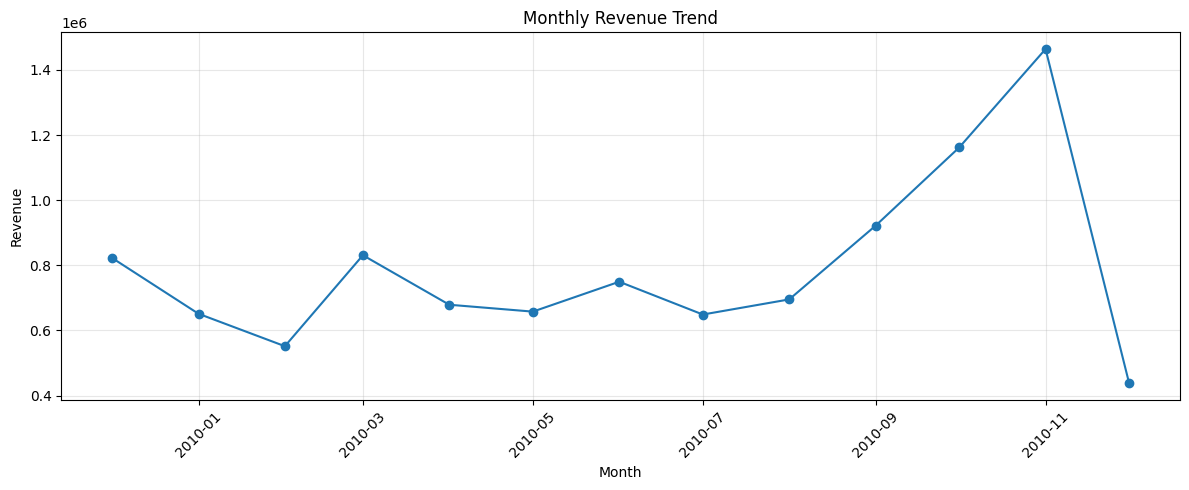

In [24]:

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/charts/monthly_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Find the highest and lowest revenue months

In [25]:
print(
    "Highest revenue month:",
    monthly_revenue.idxmax().strftime("%B %Y")
)

print(
    "Highest monthly revenue:",
    round(monthly_revenue.max(), 2)
)

print(
    "Lowest revenue month:",
    monthly_revenue.idxmin().strftime("%B %Y")
)

print(
    "Lowest monthly revenue:",
    round(monthly_revenue.min(), 2)
)

Highest revenue month: November 2010
Highest monthly revenue: 1464293.14
Lowest revenue month: December 2010
Lowest monthly revenue: 437631.02


# Customer behaviour and repeat purchases

Calculate customer purchase frequency

In [26]:
customer_sales = sales_df.dropna(
    subset=["Customer ID"]
).copy()

customer_orders = (
    customer_sales.groupby("Customer ID")["Invoice"]
    .nunique()
)

repeat_customers = (customer_orders >= 2).sum()

total_identified_customers = len(customer_orders)

repeat_rate = (
    repeat_customers / total_identified_customers * 100
    if total_identified_customers else 0
)

print("Identified customers:", total_identified_customers)
print("Repeat customers:", repeat_customers)
print(f"Repeat purchase rate: {repeat_rate:.2f}%")

Identified customers: 4312
Repeat customers: 2893
Repeat purchase rate: 67.09%


Visualize purchase frequency

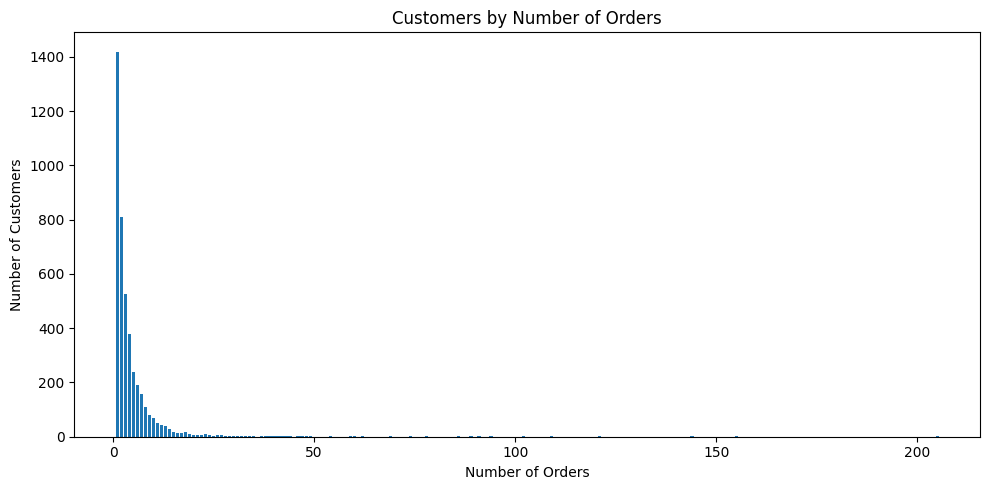

In [27]:
purchase_frequency = customer_orders.value_counts().sort_index()

plt.figure(figsize=(10, 5))

plt.bar(
    purchase_frequency.index,
    purchase_frequency.values
)

plt.title("Customers by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

Calculate revenue by customer

In [28]:
customer_revenue = (
    customer_sales.groupby("Customer ID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

display(customer_revenue.head(10))

Customer ID
18102   349,164.35
14646   248,396.50
14156   196,549.74
14911   152,121.22
13694   131,443.19
17511    84,541.17
15061    83,284.38
16684    80,489.21
16754    65,500.07
17949    60,117.60
Name: Revenue, dtype: float64

# Product performance analysis

Top 10 products by revenue

In [29]:
product_revenue = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(product_revenue)

Description
Manual                                262,589.86
REGENCY CAKESTAND 3 TIER              169,912.76
WHITE HANGING HEART T-LIGHT HOLDER    160,345.63
DOTCOM POSTAGE                        116,408.71
ASSORTED COLOUR BIRD ORNAMENT          72,890.19
PAPER CHAIN KIT 50'S CHRISTMAS         58,127.30
JUMBO BAG RED RETROSPOT                56,480.46
PARTY BUNTING                          49,664.12
POSTAGE                                49,477.54
ROTATING SILVER ANGELS T-LIGHT HLDR    47,954.49
Name: Revenue, dtype: float64

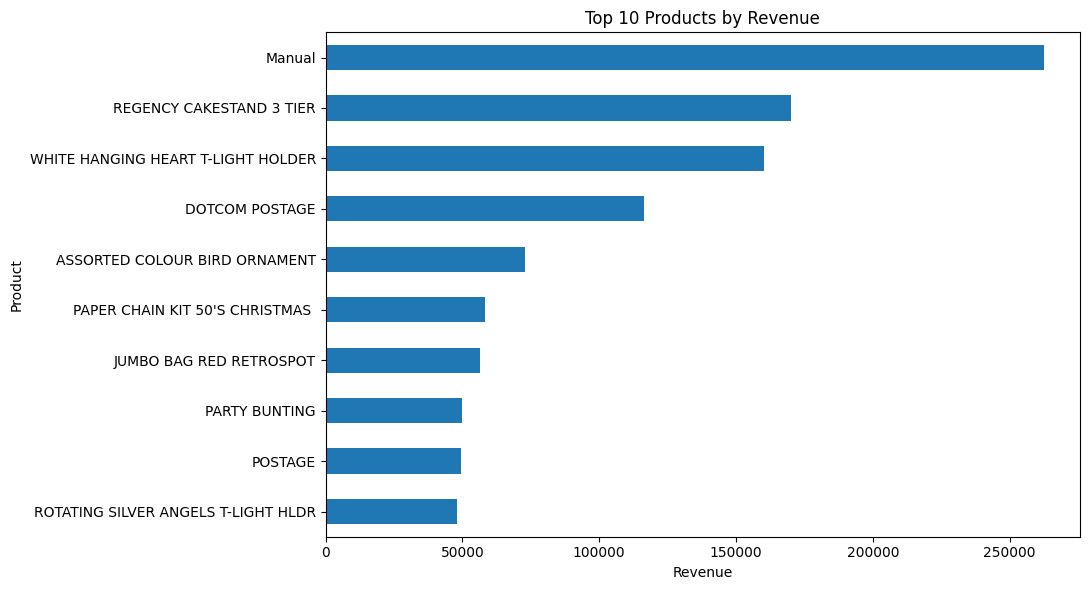

In [30]:
plt.figure(figsize=(11, 6))

product_revenue.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

Compare revenue and units sold

In [31]:
product_analysis = (
    sales_df.groupby("Description")
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Orders=("Invoice", "nunique")
    )
    .sort_values("Revenue", ascending=False)
)

display(product_analysis.head(10))

,Revenue,Units_Sold,Orders
Description,,,
Manual,"262,589.86",2768,515
REGENCY CAKESTAND 3 TIER,"169,912.76",13685,2019
WHITE HANGING HEART T-LIGHT HOLDER,"160,345.63",58691,3315
DOTCOM POSTAGE,"116,408.71",730,730
ASSORTED COLOUR BIRD ORNAMENT,"72,890.19",45228,1412
PAPER CHAIN KIT 50'S CHRISTMAS,"58,127.30",17205,957
JUMBO BAG RED RETROSPOT,"56,480.46",30746,1246
PARTY BUNTING,"49,664.12",10079,1013
POSTAGE,"49,477.54",2310,759


# Regional performance analysis

Revenue by country

In [32]:
country_analysis = (
    sales_df.groupby("Country")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("Invoice", "nunique"),
        Customers=("Customer ID", "nunique")
    )
    .sort_values("Revenue", ascending=False)
)

display(country_analysis.head(10))

,Revenue,Orders,Customers
Country,,,
United Kingdom,"8,812,311.83",19290,3969
EIRE,"380,909.57",348,5
Netherlands,"268,784.35",135,22
Germany,"202,025.39",347,67
France,"147,103.14",241,47
Sweden,"53,501.99",69,16
Denmark,"50,906.85",26,9
Spain,"47,568.65",66,25
Switzerland,"43,921.39",40,14


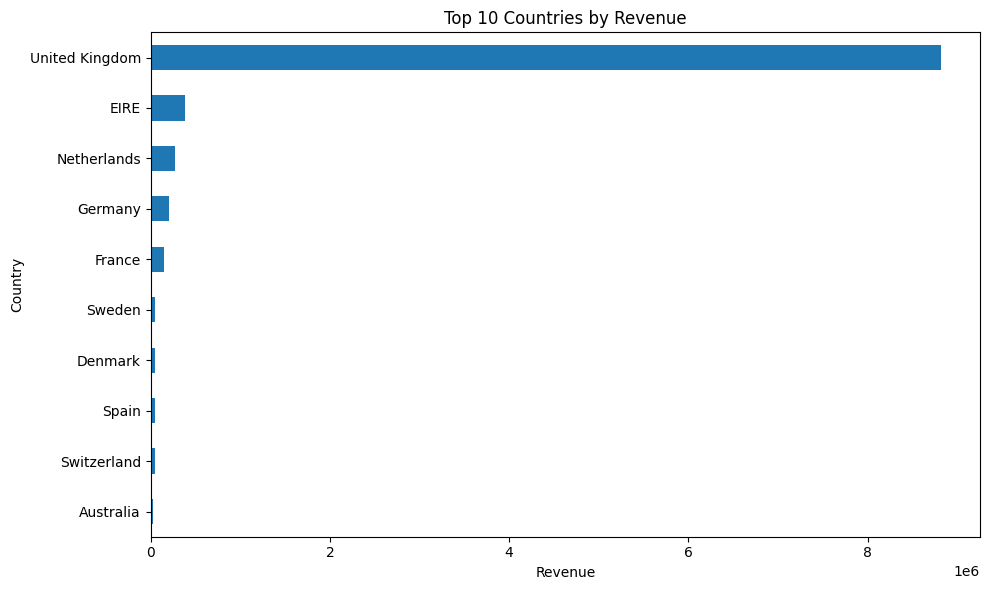

In [33]:
top_countries = country_analysis.head(10)

plt.figure(figsize=(10, 6))

top_countries["Revenue"].sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [34]:
top_10_revenue = country_analysis.head(10)["Revenue"].sum()

revenue_share = (
    top_10_revenue / total_revenue * 100
    if total_revenue else 0
)

print(f"Top 10 country revenue share: {revenue_share:.2f}%")

Top 10 country revenue share: 97.73%


# Build a structured business findings table

In [35]:
findings = pd.DataFrame({
    "Analysis Area": [
        "Revenue Trend",
        "Customer Behaviour",
        "Product Performance",
        "Regional Performance"
    ],
    "Metric to Examine": [
        "Peak and lowest monthly revenue",
        "Repeat purchase rate",
        "Top products by revenue",
        "Top 10 countries' revenue share"
    ],
    "Business Question": [
        "When is demand strongest?",
        "Do customers return to purchase?",
        "Which products drive revenue?",
        "How concentrated is revenue geographically?"
    ]
})

display(findings)

,Analysis Area,Metric to Examine,Business Question
0,Revenue Trend,Peak and lowest monthly revenue,When is demand strongest?
1,Customer Behaviour,Repeat purchase rate,Do customers return to purchase?
2,Product Performance,Top products by revenue,Which products drive revenue?
3,Regional Performance,Top 10 countries' revenue share,How concentrated is revenue geographically?


# Export results

In [36]:
from pathlib import Path

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

sales_df.to_csv(
    processed_dir / "cleaned_sales.csv",
    index=False
)

kpis.to_csv(
    processed_dir / "business_kpis.csv",
    index=False
)

monthly_revenue.to_csv(
    processed_dir / "monthly_revenue.csv"
)

print("Analysis outputs saved successfully.")

Analysis outputs saved successfully.


In [37]:
product_analysis.to_csv(
    processed_dir / "product_analysis.csv"
)

country_analysis.to_csv(
    processed_dir / "country_analysis.csv"
)

In [38]:
from pathlib import Path

# Create the output folder
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the cleaned dataset
file_path = output_dir / "cleaned_sales.csv"
sales_df.to_csv(file_path, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", file_path.resolve())
print("Total rows:", len(sales_df))
print("Total columns:", len(sales_df.columns))

Cleaned dataset saved successfully!
File location: C:\Users\dipay\OneDrive\Desktop\Code\data\processed\cleaned_sales.csv
Total rows: 504730
Total columns: 10
